# 5. Return conditioning

Se le piden al DT distintos retornos y se mide el retorno obtenido en test. Todo lo demás queda fijo:
- **Condiciones:** warm-up 0, grupo visible y grupo oculto.
- **Modelos:** los mismos 3 modelos (semillas 0, 1 y 2).
- **Retornos pedidos:** 40 a 100 cada 10, más los percentiles 10/25/50/75/90/99 de train, el máximo de train (97) y el máximo + 10 (107, fuera del soporte).

Comando: `python -m src.experimentos rc_test --logs random`.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from src.utils import OUTPUTS
from src import reporte
pd.set_option("display.width", 200)

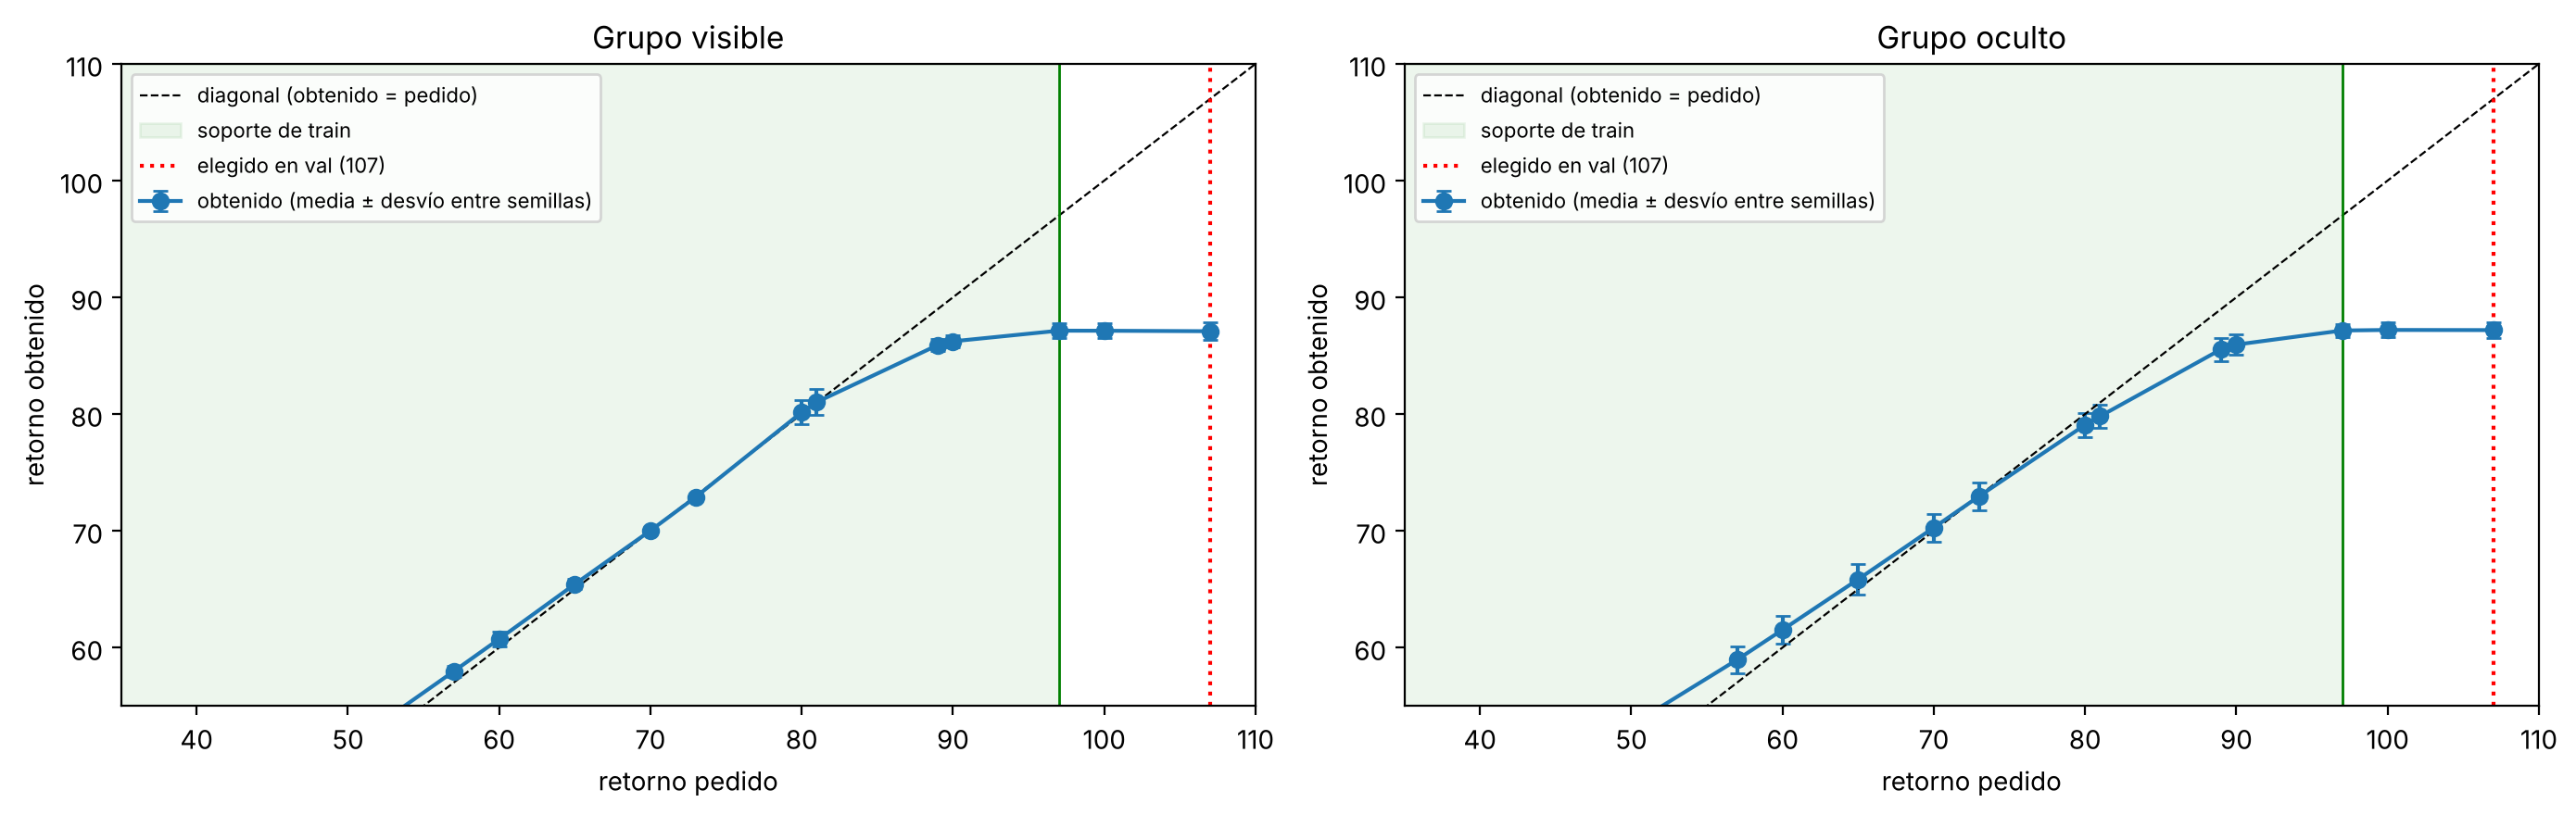

,group_visible,target,obtenido,obt_sd,norm,norm_sd
0,False,40.0,46.507,1.278,-0.612,0.042
1,False,46.0,50.314,1.176,-0.511,0.040
2,False,50.0,53.360,1.117,-0.428,0.039
3,False,57.0,58.956,1.135,-0.271,0.039
4,False,60.0,61.520,1.166,-0.197,0.038
5,False,65.0,65.845,1.273,-0.067,0.039
6,False,70.0,70.274,1.190,0.070,0.034
7,False,73.0,72.966,1.169,0.155,0.034
8,False,80.0,79.074,1.040,0.354,0.032
9,False,81.0,79.816,1.021,0.379,0.031


In [2]:
rc = pd.read_csv(OUTPUTS / "return_conditioning" / "random" / "sesiones.csv.gz")
sup = reporte.load_json("return_conditioning/random/soporte.json")["train_returns"]
elegido = reporte.load_json("seleccion/dt_random_elegido.json")
# por semilla de entrenamiento: media entre usuarios; luego media y desvío entre semillas
per_seed = rc.groupby(["group_visible", "target", "train_seed"]).agg(obtenido=("return", "mean"), norm=("normalized", "mean")).reset_index()
agg = per_seed.groupby(["group_visible", "target"]).agg(obtenido=("obtenido", "mean"), obt_sd=("obtenido", "std"),
                                                         norm=("norm", "mean"), norm_sd=("norm", "std")).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for vis, ax in zip([True, False], axes):
    a = agg[agg.group_visible == vis]
    ax.errorbar(a.target, a.obtenido, yerr=a.obt_sd, marker="o", capsize=3, label="obtenido (media ± desvío entre semillas)")
    ax.plot([20, 110], [20, 110], "k--", lw=0.8, label="diagonal (obtenido = pedido)")
    ax.axvspan(sup["min"], sup["max"], color="green", alpha=0.07, label="soporte de train")
    ax.axvline(sup["max"], color="green", lw=1)
    ax.axvline(elegido["target"], color="red", ls=":", label=f"elegido en val ({elegido['target']:.0f})")
    ax.set(title=f"Grupo {'visible' if vis else 'oculto'}", xlabel="retorno pedido", ylabel="retorno obtenido", xlim=(35, 110), ylim=(55, 110))
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
display(agg.round(3))

## 5.1 Por grupo

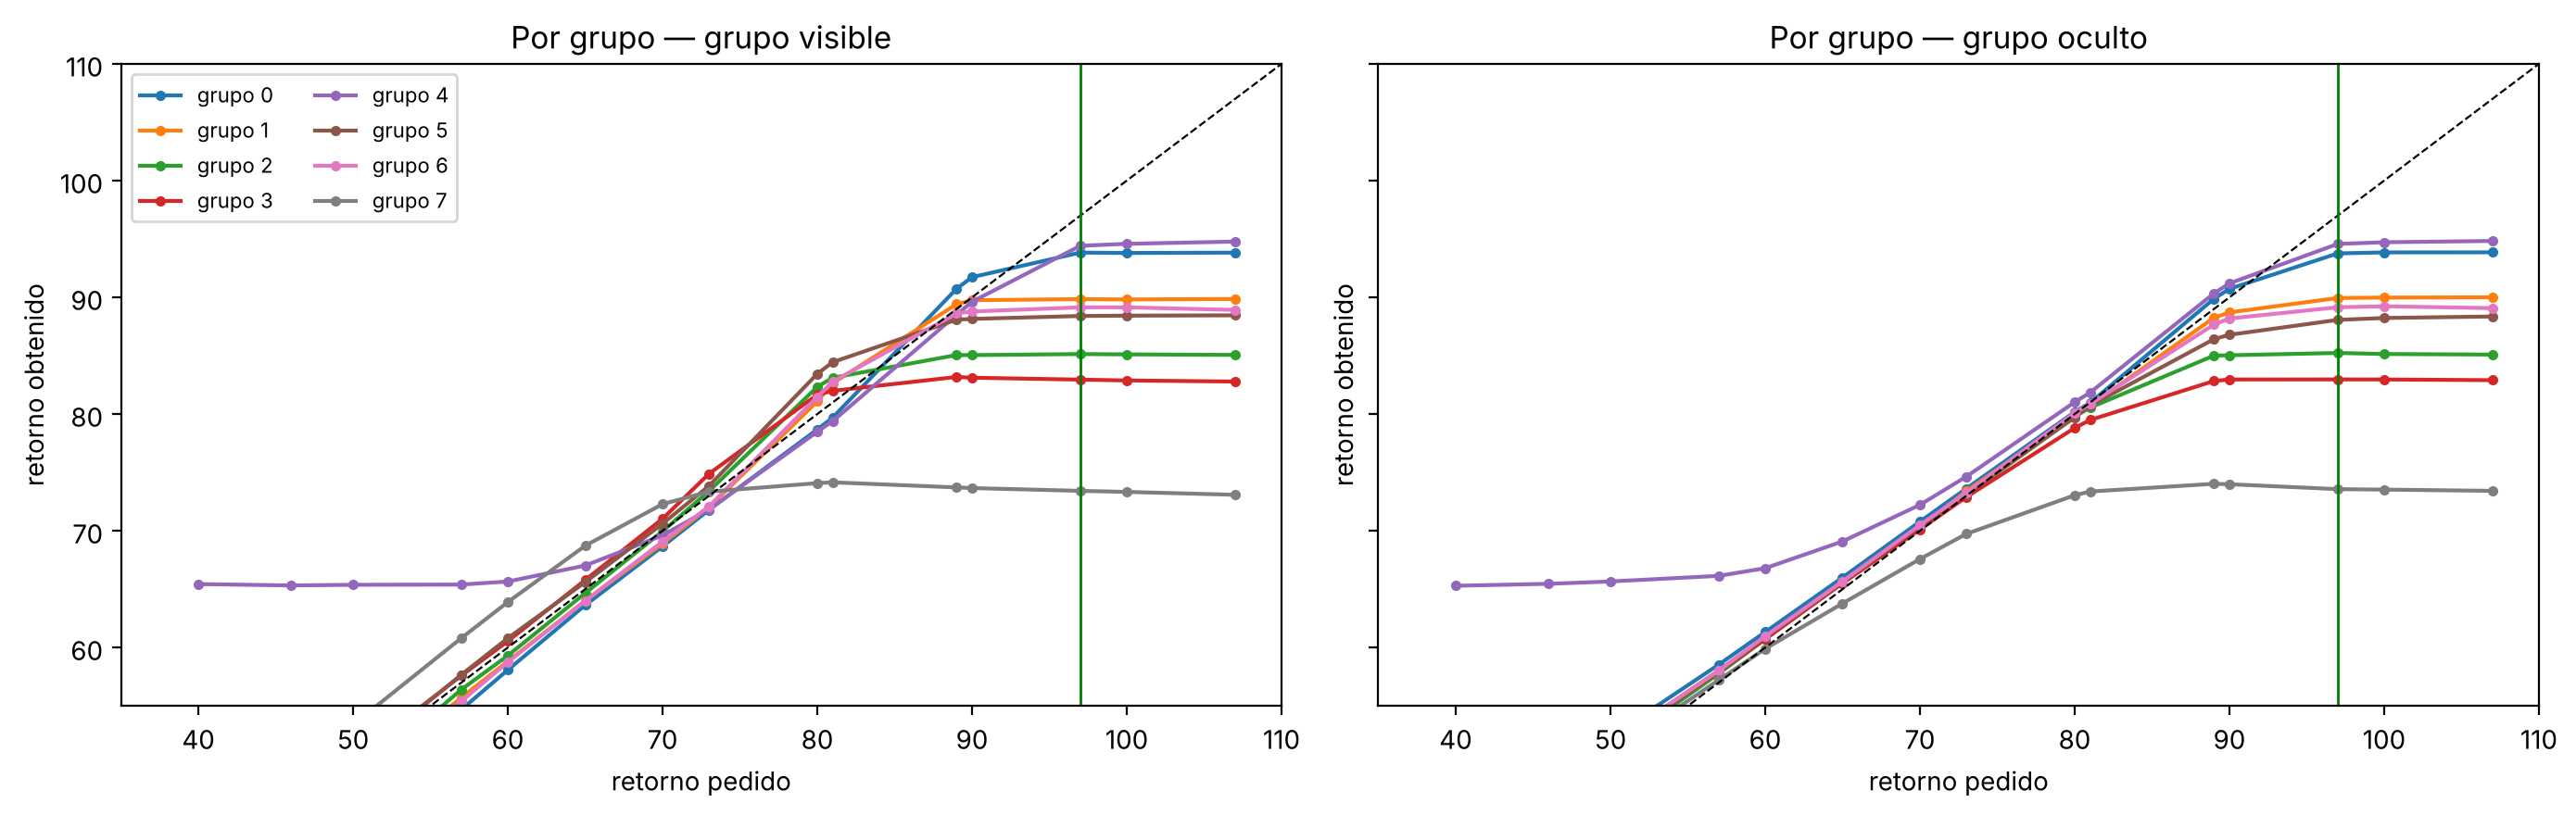

group,0,1,2,3,4,5,6,7
target,,,,,,,,
40.0,-1.225,-0.897,-0.606,-0.387,-1.053,-0.442,-0.677,-0.006
46.0,-1.184,-0.740,-0.487,-0.237,-1.059,-0.351,-0.625,0.114
50.0,-1.117,-0.606,-0.371,-0.147,-1.056,-0.256,-0.550,0.191
57.0,-0.850,-0.370,-0.160,0.019,-1.055,-0.064,-0.346,0.320
60.0,-0.712,-0.274,-0.083,0.087,-1.040,0.014,-0.245,0.373
65.0,-0.485,-0.114,0.060,0.208,-0.959,0.135,-0.087,0.457
70.0,-0.280,0.038,0.201,0.330,-0.806,0.261,0.067,0.519
73.0,-0.152,0.134,0.292,0.419,-0.673,0.342,0.157,0.538
80.0,0.129,0.415,0.530,0.576,-0.279,0.584,0.441,0.550


In [3]:
pg = rc.groupby(["group_visible", "group", "target"]).agg(obtenido=("return", "mean"), norm=("normalized", "mean")).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for vis, ax in zip([True, False], axes):
    for g in range(8):
        a = pg[(pg.group_visible == vis) & (pg.group == g)]
        ax.plot(a.target, a.obtenido, marker=".", label=f"grupo {g}")
    ax.plot([20, 110], [20, 110], "k--", lw=0.8); ax.axvline(sup["max"], color="green", lw=1)
    ax.set(title=f"Por grupo — grupo {'visible' if vis else 'oculto'}", xlabel="retorno pedido", ylabel="retorno obtenido", xlim=(35, 110), ylim=(55, 110))
axes[0].legend(fontsize=8, ncol=2); plt.tight_layout(); plt.show()
display(pg[pg.group_visible].pivot(index="target", columns="group", values="norm").round(3))

## 5.2 Incertidumbre

In [4]:
# IC 95 % por usuario del normalizado, para algunos retornos pedidos (promedio de las 3 semillas)
pu = rc.groupby(["group_visible", "target", "user_id"])["normalized"].mean().reset_index()
ic = pu.groupby(["group_visible", "target"])["normalized"].agg(media="mean", ic95=lambda x: 1.96 * x.std() / np.sqrt(len(x)))
display(ic.round(3).unstack("group_visible"))

media          ic95       
group_visible  False  True   False  True 
target                                   
40.0          -0.612 -0.662  0.018  0.019
46.0          -0.511 -0.571  0.019  0.020
50.0          -0.428 -0.489  0.019  0.021
57.0          -0.271 -0.313  0.019  0.021
60.0          -0.197 -0.235  0.019  0.021
65.0          -0.067 -0.098  0.018  0.021
70.0           0.070  0.041  0.016  0.019
73.0           0.155  0.132  0.015  0.018
80.0           0.354  0.368  0.010  0.014
81.0           0.379  0.398  0.010  0.013
89.0           0.586  0.591  0.004  0.006
90.0           0.602  0.606  0.004  0.006
97.0           0.655  0.654  0.005  0.005
100.0          0.657  0.655  0.005  0.005
107.0          0.657  0.655  0.005  0.005

**Cómo leerlo:**
- **Sobre la diagonal:** el modelo obtiene lo que se le pide.
- **Por debajo y plano:** el modelo no distingue entre pedir un poco más o un poco menos.
- **Más allá del máximo de train (97):** el modelo nunca vio esos valores; lo que haga ahí es extrapolación.

La interpretación completa está en `docs/REPORTE.md`.